<a href="https://colab.research.google.com/github/adamarsyadfaizin/PCVK26_10_Adam/blob/main/PCVK_W10_244107020164_Adam_A_F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pembelajaran Deteksi Objek

# Pendahuluan

Praktikum Modul 10 membahas dasar-dasar deteksi objek dan penerapannya menggunakan OpenCV pada Python. Kegiatan praktikum mencakup deteksi objek dasar, pencocokan fitur, deteksi wajah, serta pengenalan karakter menggunakan Convolutional Neural Network (CNN).

## Ruang Lingkup Praktikum

- **D1 – Deteksi Objek Dasar:** template matching, template matching manual, edge detection, corner detection, grid detection, dan contour detection.
- **D2 – Feature Matching dan Face Detection:** pencocokan fitur ORB dan SIFT, deteksi wajah manusia dan kucing, deteksi mata dan senyuman, face tracking, blurring, serta pengolahan KTM.
- **D3 – Tugas Pengayaan:** klasifikasi karakter angka 0–9 menggunakan CNN.

## Sumber Data Gambar

Gambar untuk praktikum D1 dan D2 disediakan pada [folder Google Drive Modul 10](https://drive.google.com/drive/folders/1M30vcqgPBD1PHQpqFUtxWdtiMrwSpijC?usp=drive_link). Berkas gambar diekstrak dan disusun dalam direktori praktikum sebelum diproses.

| Bagian | Nama file |
|---|---|
| Template matching | `cats_and_bunnies.jpg`, `cat2_templatejpg.jpg` |
| Template matching manual | `bahrain.jpg`, `bahrain-template.jpg` |
| Edge detection | `car-park.jpg` |
| Corner detection | `chess-board.jpg` |
| Grid detection | `sudoku.jpg` |
| Contour detection | `laptop.jpg` |
| ORB/SIFT | `facedet/reeses_puffs.png`, `facedet/many_cereals.jpg` |
| Deteksi wajah | `facedet/prabowo.jpg` dan gambar lain pada folder `facedet` |
| Deteksi wajah kucing | `cat2_templatejpg.jpg` |
| Pengolahan KTM | Foto KTM sebagai citra acuan dan foto KTM yang sama pada lingkungan dengan objek lain |

## Dasar Pelaksanaan

1. Metode pada D1 memproses citra masukan secara langsung dan tidak memerlukan proses pelatihan model.
2. ORB dan SIFT melakukan pencarian serta pencocokan fitur antara citra acuan dan citra sumber. Haar Cascade menggunakan classifier yang telah dilatih sebelumnya.
3. Pelatihan CNN dilakukan pada D3. Model mempelajari pola visual dari potongan karakter angka yang telah diberi label, bukan mendeteksi lokasi KTM pada citra penuh.

# Deteksi Objek Dasar

## Langkah 1: Persiapan Awal

In [ ]:
import os
import cv2 as cv
import numpy as np
from pathlib import Path
from matplotlib import pyplot as plt

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print('Notebook berjalan di luar Google Colab.')

if IN_COLAB:
    kandidat_root = [
        Path('/content/drive/MyDrive/PCVK/Pertemuan 10'),
        Path('/content/drive/MyDrive/PCVK/Images'),
        Path('/content/drive/MyDrive/Polinema/Kuliah/PCVK/Images'),
        Path('/content/drive/MyDrive/Images'),
    ]
else:
    kandidat_root = [Path.cwd() / 'Pertemuan 10', Path.cwd() / 'Images']

DATA_ROOT = next((p for p in kandidat_root if p.is_dir()), kandidat_root[0])
print('Folder gambar praktikum:', DATA_ROOT)
if not DATA_ROOT.is_dir():
    print('PERINGATAN: folder gambar tidak ditemukan. Periksa lokasi Google Drive.')

EKSTENSI_GAMBAR = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def cari_file(nama_file):
    """Cari file di folder sumber praktikum dan subfolder-nya."""
    candidato = Path(nama_file)
    if candidato.is_absolute() and candidato.is_file():
        return candidato
    nama_dicari = candidato.name.casefold()
    for root in [DATA_ROOT, Path.cwd()]:
        if not root.is_dir():
            continue
        langsung = root / candidato.name
        if langsung.is_file():
            return langsung
        for p in root.rglob('*'):
            if p.is_file() and p.name.casefold() == nama_dicari:
                return p
    stem = candidato.stem.casefold()
    for root in [DATA_ROOT, Path.cwd()]:
        if root.is_dir():
            alternatif = [p for p in root.rglob('*')
                          if p.is_file() and p.suffix.casefold() in EKSTENSI_GAMBAR
                          and p.stem.casefold() == stem]
            if alternatif:
                print(f'Info: {nama_file} tidak ditemukan persis; memakai {sorted(alternatif)[0].name}.')
                return sorted(alternatif)[0]
    raise FileNotFoundError(
        f"File '{nama_file}' tidak ditemukan di {DATA_ROOT}. Periksa nama dan lokasi file."
    )

def baca_warna(nama_file):
    path = cari_file(nama_file)
    gambar = cv.imread(str(path), cv.IMREAD_COLOR)
    if gambar is None:
        raise ValueError(f'OpenCV gagal membaca gambar: {path}')
    return gambar

def baca_gray(nama_file):
    path = cari_file(nama_file)
    gambar = cv.imread(str(path), cv.IMREAD_GRAYSCALE)
    if gambar is None:
        raise ValueError(f'OpenCV gagal membaca gambar: {path}')
    return gambar

def baca_cascade(nama_xml):
    """Cari XML Haar Cascade pada folder haarcascades atau instalasi OpenCV."""
    kandidat = [
        DATA_ROOT / 'haarcascades' / nama_xml,
        DATA_ROOT.parent / 'haarcascades' / nama_xml,
        Path(cv.data.haarcascades) / nama_xml,
    ]
    if DATA_ROOT.is_dir():
        kandidat.extend(DATA_ROOT.rglob(nama_xml))
    for path in kandidat:
        if Path(path).is_file():
            cascade = cv.CascadeClassifier(str(path))
            if not cascade.empty():
                return cascade
    raise FileNotFoundError(f"Cascade '{nama_xml}' tidak ditemukan di {DATA_ROOT} atau folder OpenCV.")

print('Pemeriksaan awal selesai. DATA_ROOT =', DATA_ROOT)

Mounted at /content/drive
Folder gambar praktikum: /content/drive/MyDrive/PCVK/Pertemuan 10
Pemeriksaan awal selesai. DATA_ROOT = /content/drive/MyDrive/PCVK/Pertemuan 10


In [ ]:
KTM_FILE = 'KTM1b.jpg'

KTM_SCENE_FILE = 'KTM_scene.jpg'

print('DATA_ROOT      :', DATA_ROOT)
print('KTM_FILE       :', KTM_FILE)
print('KTM_SCENE_FILE :', KTM_SCENE_FILE)

DATA_ROOT      : /content/drive/MyDrive/PCVK/Pertemuan 10
KTM_FILE       : KTM1b.jpg
KTM_SCENE_FILE : KTM_scene.jpg


## Hasil Persiapan

Direktori gambar praktikum berhasil dikenali dan fungsi pembacaan citra serta classifier Haar Cascade telah disiapkan.

Pada bagian Smile Detection, program terlebih dahulu mencari `people.jpg`. Apabila berkas tersebut tidak tersedia, program menggunakan `solvayconf.jpg` sebagai citra alternatif yang tersedia pada direktori `facedet`.

Citra acuan KTM menggunakan `KTM1b.jpg` yang berada pada folder identitas praktikan. Deteksi KTM pada foto bersama objek lain memerlukan citra tambahan bernama `KTM_scene.jpg`. Bagian tersebut hanya dapat diproses apabila foto adegan tersedia.

Dataset karakter angka untuk pengayaan CNN diproses pada direktori kerja lokal Colab agar pembacaan gambar tidak bergantung pada akses berulang ke Google Drive.

## Langkah 2: Pencocokan Pola Menggunakan OpenCV

Proses ini membandingkan gambar acuan kecil dengan gambar utama secara menyeluruh untuk mengukur kecocokan menggunakan enam variasi fungsi pencocokan.

In [ ]:
img = baca_warna('cats_and_bunnies.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
template = baca_gray('cat2_templatejpg.jpg')

h, w = template.shape
if h > img_gray.shape[0] or w > img_gray.shape[1]:
    raise ValueError('Ukuran template tidak boleh lebih besar dari source image.')

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Source image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('Template image')
plt.axis('off')
plt.show()

In [ ]:
daftar_metode = [
    ('TM_SQDIFF', cv.TM_SQDIFF),
    ('TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED),
    ('TM_CCORR', cv.TM_CCORR),
    ('TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
    ('TM_CCOEFF', cv.TM_CCOEFF),
    ('TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
]

for nama_metode, method in daftar_metode:
    hasil = img_rgb.copy()
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    top_left = min_loc if method in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED) else max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(hasil, top_left, bottom_right, (255, 0, 0), 3)

    plt.figure(figsize=(10, 4))
    plt.suptitle(nama_metode)
    plt.subplot(1, 2, 1)
    plt.imshow(res, cmap='gray')
    plt.title('Matching result')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(hasil)
    plt.title('Lokasi kecocokan terbaik')
    plt.axis('off')
    plt.show()

**Hasil dan pembahasan:** Keenam metode membandingkan pola pada citra sumber dan citra template. Metode `TM_SQDIFF` memilih nilai minimum sebagai kecocokan terbaik, sedangkan metode korelasi dan koefisien memilih nilai maksimum. Hasil pencocokan dipengaruhi oleh ukuran template, pencahayaan, dan kemiripan pola pada gambar.

## Langkah 3: Pencocokan Pola Kustom Multi-Objek

Langkah ini mendeteksi keberadaan beberapa objek sejenis secara manual menggunakan perhitungan korelasi silang ternormalisasi tanpa bantuan fungsi bawaan OpenCV.

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view
from matplotlib.patches import Rectangle

img = baca_warna('bahrain.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY).astype(np.float32)
template = baca_gray('bahrain-template.jpg').astype(np.float32)
h, w = template.shape

if h > gray.shape[0] or w > gray.shape[1]:
    raise ValueError('Template Bahrain lebih besar daripada source image.')

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Source image: Bahrain')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('Template Bahrain')
plt.axis('off')
plt.show()

In [ ]:
def template_matching(I, T):
    """Normalized cross-correlation sederhana tanpa cv.matchTemplate()."""
    th, tw = T.shape
    H, W = I.shape
    if th > H or tw > W:
        raise ValueError('Ukuran template harus lebih kecil dari citra input.')

    T0 = T - T.mean()
    T_norm = np.sqrt((T0 ** 2).sum())
    R = np.zeros((H - th + 1, W - tw + 1), dtype=np.float32)

    for y in range(H - th + 1):
        strip = I[y:y + th, :]
        jendela = sliding_window_view(strip, (th, tw))[0]
        J0 = jendela - jendela.mean(axis=(1, 2), keepdims=True)
        pembilang = (J0 * T0).sum(axis=(1, 2))
        penyebut = np.sqrt((J0 ** 2).sum(axis=(1, 2))) * T_norm
        R[y] = pembilang / (penyebut + 1e-8)
    return R

R = template_matching(gray, template)
print('Ukuran matriks hasil:', R.shape)
print('Skor kecocokan maksimum:', round(float(R.max()), 3))

In [ ]:
threshold = 0.45
kandidat = np.argwhere(R >= threshold)
skor = R[kandidat[:, 0], kandidat[:, 1]]
urut = np.argsort(-skor)

kotak = []
for idx in urut:
    y, x = kandidat[idx]
    bertumpuk = any(
        abs(y - by) < h * 0.5 and abs(x - bx) < w * 0.5
        for by, bx in kotak
    )
    if not bertumpuk:
        kotak.append((y, x))

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(img_rgb)
for y, x in kotak:
    ax.add_patch(Rectangle((x, y), w, h, edgecolor='yellow', facecolor='none', linewidth=2))
ax.set_title('Multiple object template matching manual')
ax.axis('off')
plt.show()
print('Jumlah objek yang lolos threshold:', len(kotak))

**Hasil dan pembahasan:** Template matching manual menghasilkan sejumlah kandidat lokasi objek berdasarkan nilai korelasi. Nilai ambang (*threshold*) digunakan untuk menyaring kandidat, sedangkan proses *non-maximum suppression* mengurangi kotak deteksi yang saling bertumpuk.

## Langkah 4: Deteksi Tepi Gambar

Menemukan kontur tepi objek dengan membandingkan tiga teknik utama: Sobel, Canny, dan Laplacian.

In [ ]:
img = baca_warna('car-park.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)

### Penerapan Metode Sobel

In [ ]:
sobel_x = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)
abs_x = cv.convertScaleAbs(sobel_x)
abs_y = cv.convertScaleAbs(sobel_y)
sobel = cv.addWeighted(abs_x, 0.5, abs_y, 0.5, 0)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Citra asli')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(sobel, cmap='gray')
plt.title('Sobel')
plt.axis('off')
plt.show()

### Penerapan Metode Canny

In [ ]:
canny = cv.Canny(blur, 100, 200)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Citra asli')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(canny, cmap='gray')
plt.title('Canny')
plt.axis('off')
plt.show()

### Penerapan Metode Laplacian

In [ ]:
laplacian = cv.Laplacian(blur, cv.CV_64F)
laplacian = cv.convertScaleAbs(laplacian)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Citra asli')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian')
plt.axis('off')
plt.show()

**Hasil dan pembahasan:** Sobel menghitung perubahan intensitas pada arah horizontal dan vertikal. Canny menghasilkan garis tepi melalui tahapan penghalusan, perhitungan gradien, penipisan tepi, dan *hysteresis thresholding*. Laplacian menonjolkan perubahan intensitas berdasarkan turunan kedua dan lebih sensitif terhadap noise.

## Langkah 5: Deteksi Titik Sudut Gambar

Menemukan lokasi koordinat sudut pada pola kotak-kotak menggunakan algoritma Harris dan Shi-Tomasi.

In [ ]:
img = baca_warna('chess-board.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

### Deteksi Sudut Harris

In [ ]:
gray32 = np.float32(gray)
dst = cv.cornerHarris(gray32, blockSize=2, ksize=3, k=0.04)
dst = cv.dilate(dst, None)
hasil_harris = img_rgb.copy()
hasil_harris[dst > 0.01 * dst.max()] = [255, 0, 0]

plt.figure(figsize=(8, 8))
plt.imshow(hasil_harris)
plt.title('Harris Corner Detection')
plt.axis('off')
plt.show()

### Deteksi Sudut Shi-Tomasi

In [ ]:
corners = cv.goodFeaturesToTrack(gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
hasil_shi = img_rgb.copy()
if corners is not None:
    corners = np.int32(corners)
    for titik in corners:
        x, y = titik.ravel()
        cv.circle(hasil_shi, (x, y), 5, (255, 0, 0), -1)
    jumlah_sudut = len(corners)
else:
    jumlah_sudut = 0

plt.figure(figsize=(8, 8))
plt.imshow(hasil_shi)
plt.title('Shi-Tomasi Corner Detection')
plt.axis('off')
plt.show()
print('Jumlah sudut Shi-Tomasi:', jumlah_sudut)

**Hasil dan pembahasan:** Harris menentukan titik sudut berdasarkan perubahan intensitas pada beberapa arah. Shi-Tomasi memilih titik sudut berdasarkan nilai eigen minimum, dengan pengaturan jumlah titik, kualitas minimum, dan jarak antartitik.

## Langkah 6: Pemetaan Pola Kisi Berdasarkan Transformasi Hough

Mengidentifikasi struktur garis kisi pada papan Sudoku melalui metode deteksi tepi yang dilanjutkan dengan pencarian parameter garis.

In [ ]:
img = baca_warna('sudoku.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
img_blur = cv.GaussianBlur(gray, (5, 5), 0)
edges = cv.Canny(img_blur, 30, 200, apertureSize=3)

kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(edges, kernel, iterations=1)
erosi = cv.erode(dilasi, kernel, iterations=1)

plt.figure(figsize=(14, 4))
for i, (gambar, judul) in enumerate([
    (edges, '1. Canny'), (dilasi, '2. Dilasi'), (erosi, '3. Erosi')
], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(gambar, cmap='gray')
    plt.title(judul)
    plt.axis('off')
plt.show()

In [ ]:
lines = cv.HoughLines(erosi, rho=1, theta=np.pi / 180, threshold=90)
print('Jumlah garis hasil HoughLines:', 0 if lines is None else len(lines))

Jumlah garis setelah penggabungan: 49


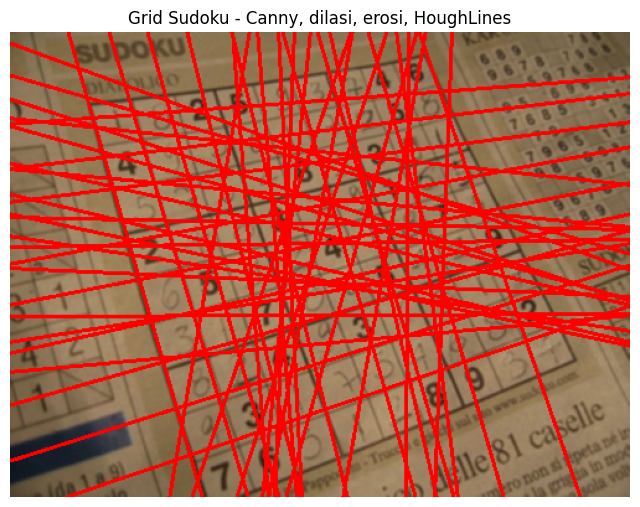

In [ ]:
def gabung_garis(lines, selisih_rho=20, selisih_theta=np.pi / 18):
    """Mengelompokkan garis yang dekat dan memiliki arah hampir sama."""
    if lines is None:
        return []

    kelompok = []
    for rho, theta in lines[:, 0]:
        deg = np.rad2deg(theta)
        is_vertical = (deg < 20) or (deg > 160)
        is_horizontal = 70 < deg < 110
        if not (is_vertical or is_horizontal):
            continue

        if rho < 0:
            rho, theta = -rho, theta - np.pi

        for grup in kelompok:
            r0, t0 = grup[0]
            beda_theta = abs(theta - t0)
            beda_theta = min(beda_theta, 2 * np.pi - beda_theta)
            if abs(rho - r0) < selisih_rho and beda_theta < selisih_theta:
                grup.append((rho, theta))
                break
        else:
            kelompok.append([(rho, theta)])

    hasil = []
    for grup in kelompok:
        rho_rata = np.mean([r for r, _ in grup])
        theta_rata = np.arctan2(
            np.mean([np.sin(t) for _, t in grup]),
            np.mean([np.cos(t) for _, t in grup])
        )
        hasil.append((rho_rata, theta_rata))
    return hasil

garis_gabung = gabung_garis(lines)
print('Jumlah garis setelah penggabungan:', len(garis_gabung))
hasil = img_rgb.copy()
H, W = gray.shape
panjang_garis = max(H, W) * 2
for rho, theta in garis_gabung:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    pt1 = (int(x0 + panjang_garis * (-b)), int(y0 + panjang_garis * a))
    pt2 = (int(x0 - panjang_garis * (-b)), int(y0 - panjang_garis * a))
    cv.line(hasil, pt1, pt2, (255, 0, 0), 2)

plt.figure(figsize=(8, 7))
plt.imshow(hasil)
plt.title('Grid Sudoku - Canny, dilasi, erosi, HoughLines')
plt.axis('off')
plt.show()

**Hasil dan pembahasan:** Deteksi grid dilakukan dengan menerapkan Canny, dilasi, dan erosi sebelum pencarian garis menggunakan Hough Transform. Penggabungan garis digunakan untuk mengurangi garis duplikat yang memiliki posisi berdekatan dan arah hampir sama.

## Langkah 7: Segmentasi Menggunakan Kontur Gambar

Mengidentifikasi wujud bentuk fisik laptop berdasarkan pengolahan citra biner dan deteksi kontur tepi luarnya.

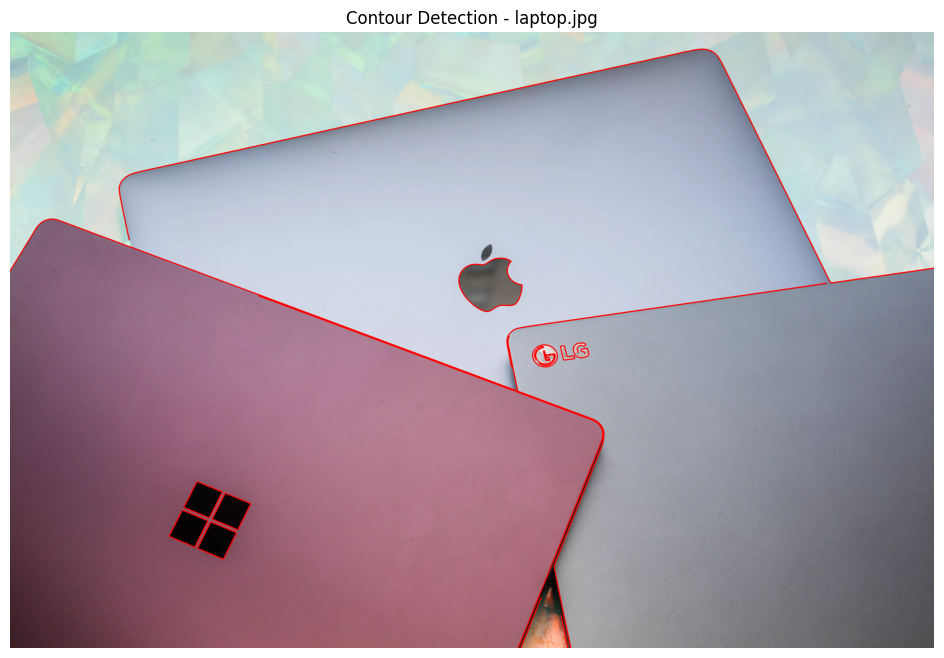

Jumlah kontur yang digambar: 23


In [ ]:
img = baca_warna('laptop.jpg')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(gray, (9, 9), 0)
edges = cv.Canny(blur, 30, 100)

contours, hierarchy = cv.findContours(edges, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

kontur_laptop = [c for c in contours if cv.arcLength(c, True) > 200]

hasil = img_rgb.copy()
cv.drawContours(hasil, kontur_laptop, -1, (255, 0, 0), 3)
plt.figure(figsize=(12, 8))
plt.imshow(hasil)
plt.title('Contour Detection - laptop.jpg')
plt.axis('off')
plt.show()
print('Jumlah kontur yang digambar:', len(kontur_laptop))

**Hasil dan pembahasan:** Fungsi `findContours()` mengambil batas objek dari citra biner. Panjang kontur dihitung menggunakan `cv.arcLength(contour, True)`, dengan parameter `True` menandakan bahwa kontur diperlakukan sebagai kurva tertutup. Jumlah kontur yang diperoleh dipengaruhi kualitas citra tepi dan penyaringan panjang kontur.

# Pembelajaran Fitur dan Deteksi Wajah

## Langkah 8: Feature Matching Menggunakan ORB

Objek acuan: `reeses_puffs.png`. Gambar utama: `many_cereals.jpg`. Kedua gambar berasal dari folder `Images/facedet` yang disediakan modul.

In [ ]:
def display(img, cmap='gray', title=None):
    plt.figure(figsize=(12, 8))
    plt.imshow(img, cmap=cmap)
    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

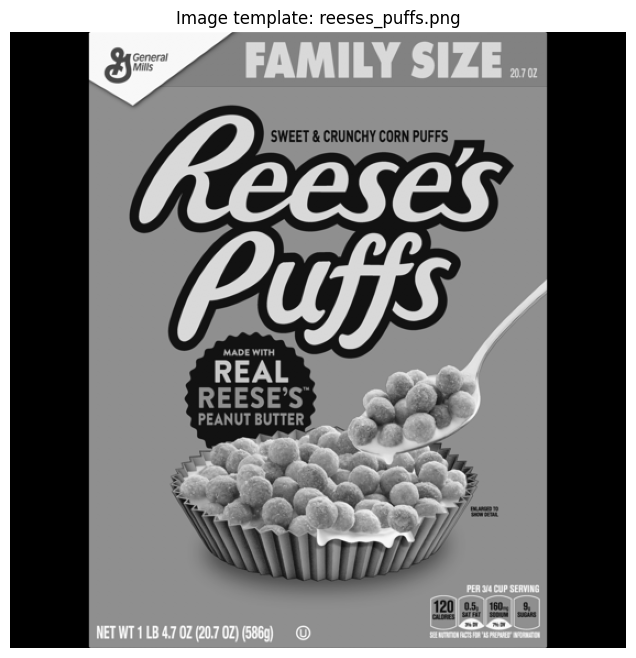

In [ ]:
reeses = baca_gray('reeses_puffs.png')
display(reeses, title='Image template: reeses_puffs.png')

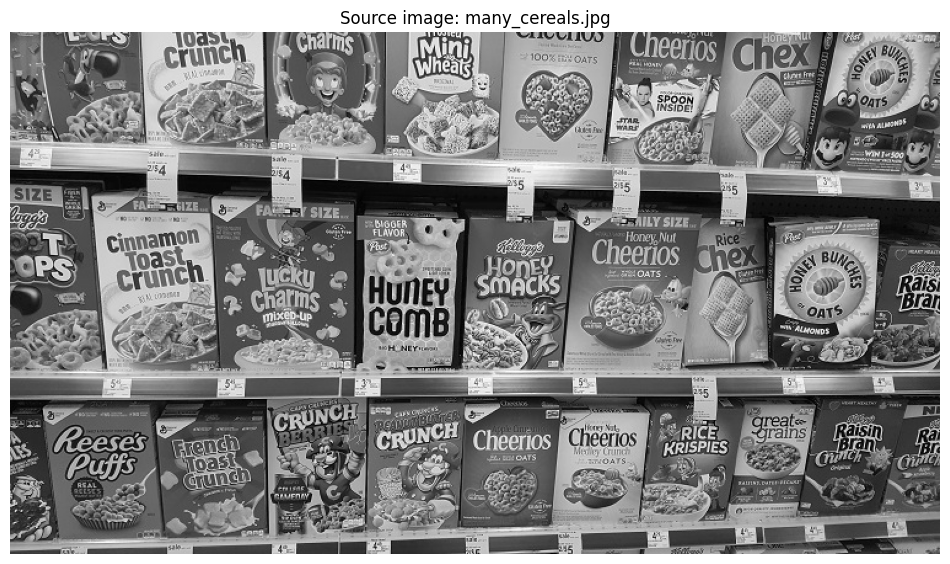

In [ ]:
cereals = baca_gray('many_cereals.jpg')
display(cereals, title='Source image: many_cereals.jpg')

In [ ]:
orb = cv.ORB_create()
kp1, des1 = orb.detectAndCompute(reeses, None)
kp2, des2 = orb.detectAndCompute(cereals, None)
if des1 is None or des2 is None:
    raise ValueError('Fitur ORB tidak ditemukan. Periksa kualitas gambar acuan dan gambar utama.')

bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda m: m.distance)
print('Jumlah keypoint template:', len(kp1))
print('Jumlah keypoint source  :', len(kp2))
print('Jumlah pasangan ORB     :', len(matches))

Jumlah keypoint template: 500
Jumlah keypoint source  : 500
Jumlah pasangan ORB     : 139


In [ ]:
if matches:
    print('Distance pasangan terbaik:', round(matches[0].distance, 2))
else:
    print('Tidak ada pasangan fitur yang cocok.')

Distance pasangan terbaik: 42.0


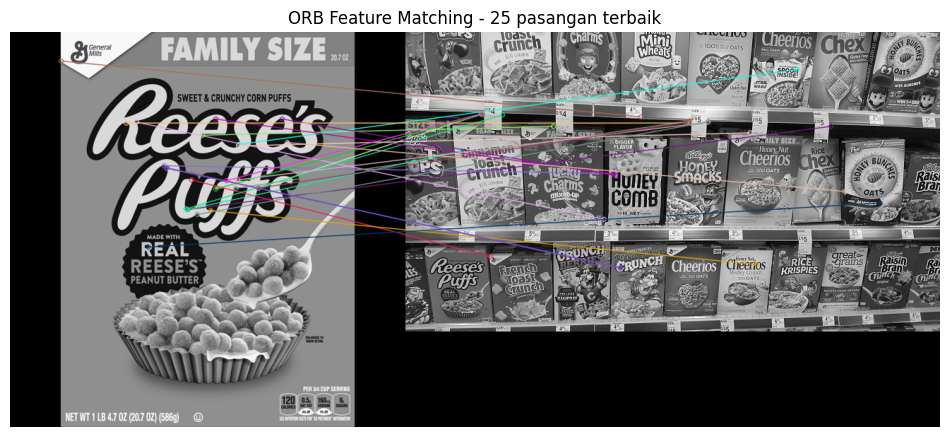

In [ ]:
if matches:
    orb_matches = cv.drawMatches(
        reeses, kp1, cereals, kp2, matches[:25], None,
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    display(orb_matches, cmap=None, title='ORB Feature Matching - 25 pasangan terbaik')

**Hasil dan pembahasan:** ORB mendeteksi *keypoint* dan membentuk deskriptor biner. Pencocokan dilakukan menggunakan *Hamming distance*. Nilai jarak yang lebih kecil menunjukkan deskriptor yang lebih mirip, tetapi setiap pasangan fitur tetap perlu diperiksa melalui hasil visual.

## Langkah 9: Feature Matching Menggunakan SIFT

Langkah ini memakai dua gambar yang sama seperti ORB, tetapi deskriptor dan pencocokannya menggunakan SIFT serta Lowe Ratio Test.

In [ ]:
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(reeses, None)
kp2, des2 = sift.detectAndCompute(cereals, None)
if des1 is None or des2 is None:
    raise ValueError('Fitur SIFT tidak ditemukan. Periksa kedua gambar.')

bf = cv.BFMatcher()
semua_pasangan = bf.knnMatch(des1, des2, k=2)
good = []
for pasangan in semua_pasangan:
    if len(pasangan) == 2:
        m, n = pasangan
        if m.distance < 0.75 * n.distance:
            good.append([m])
print('Jumlah pasangan SIFT:', len(semua_pasangan))
print('Jumlah good matches:', len(good))

Jumlah pasangan SIFT: 1501
Jumlah good matches: 79


In [ ]:
print('Jumlah good matches SIFT:', len(good))

Jumlah good matches SIFT: 79


In [ ]:
print('Jumlah pasangan kandidat SIFT:', len(semua_pasangan))

Jumlah pasangan kandidat SIFT: 1501


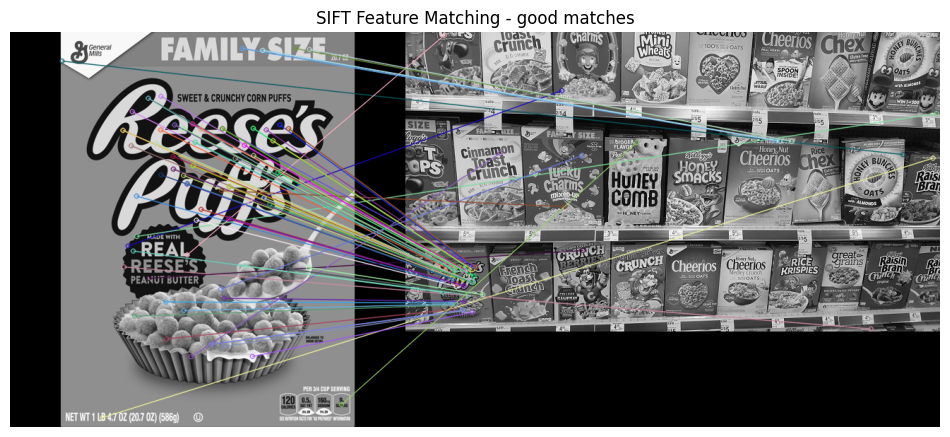

In [ ]:
sift_matches = cv.drawMatchesKnn(
    reeses, kp1, cereals, kp2, good, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
display(sift_matches, cmap=None, title='SIFT Feature Matching - good matches')

**Hasil dan pembahasan:** SIFT menghasilkan *keypoint* dan deskriptor yang digunakan dalam proses pencocokan. Lowe Ratio Test menyaring pasangan fitur berdasarkan perbandingan jarak dua kandidat terdekat. Hasil visual digunakan untuk menilai apakah pasangan fitur benar-benar sesuai dengan objek yang dicari.

## Langkah 10: Face Detection Manusia

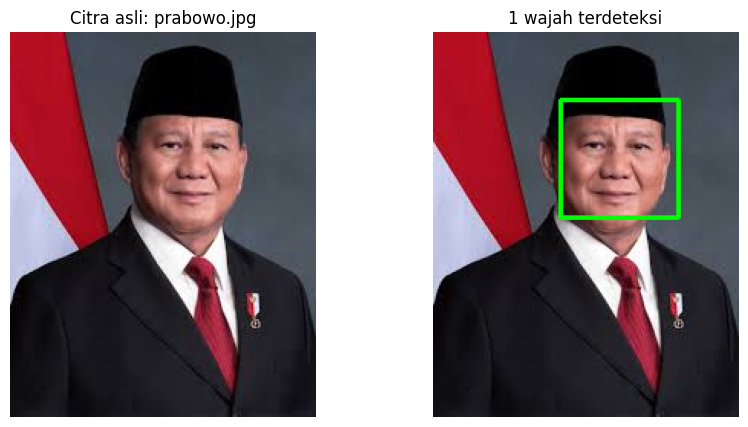

Jumlah wajah terdeteksi: 1


In [ ]:
img = baca_warna('prabowo.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
cascade_wajah = baca_cascade('haarcascade_frontalface_alt.xml')
roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)

hasil = img.copy()
for (x, y, w, h) in roi_wajah:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra asli: prabowo.jpg')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title(f'{len(roi_wajah)} wajah terdeteksi')
plt.axis('off')
plt.show()
print('Jumlah wajah terdeteksi:', len(roi_wajah))

**Hasil dan pembahasan:** Haar Cascade menggunakan classifier XML yang telah dilatih sebelumnya. Fungsi `detectMultiScale()` mencari kandidat wajah pada citra. Jumlah deteksi dapat dipengaruhi ukuran gambar, pencahayaan, dan parameter yang digunakan.

## Langkah 11: Face Detection Kucing

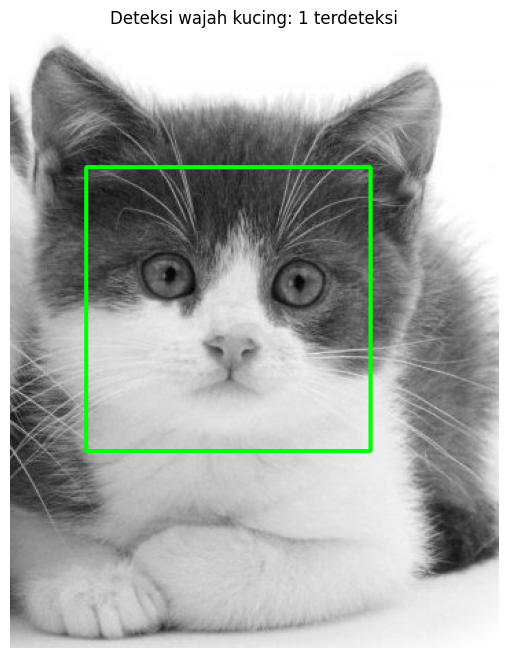

Jumlah wajah kucing terdeteksi: 1


In [ ]:
kucing = baca_gray('cat2_templatejpg.jpg')
cascade_kucing = baca_cascade('haarcascade_frontalcatface.xml')
roi_kucing = cascade_kucing.detectMultiScale(
    kucing, scaleFactor=1.1, minNeighbors=3, minSize=(40, 40)
)

hasil = cv.cvtColor(kucing, cv.COLOR_GRAY2BGR)
for (x, y, w, h) in roi_kucing:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title(f'Deteksi wajah kucing: {len(roi_kucing)} terdeteksi')
plt.axis('off')
plt.show()
print('Jumlah wajah kucing terdeteksi:', len(roi_kucing))

**Hasil dan pembahasan:** Deteksi wajah kucing menggunakan classifier khusus kucing, yaitu `haarcascade_frontalcatface.xml`. Classifier ini berbeda dari classifier wajah manusia sehingga perlu disesuaikan dengan objek yang dideteksi.

## Langkah 12: Eyes Detection pada Wajah Pak Prabowo

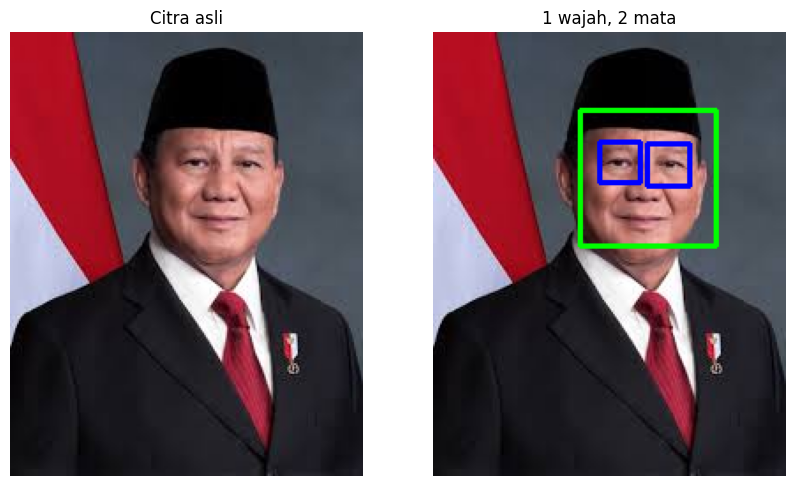

Wajah: 1 | Mata: 2


In [ ]:
img = baca_warna('prabowo.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
cascade_wajah = baca_cascade('haarcascade_frontalface_alt.xml')
cascade_mata = baca_cascade('haarcascade_eye.xml')

hasil = img.copy()
roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
jumlah_mata = 0
for (x, y, w, h) in roi_wajah:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)
    roi_gray = gray[y:y + h, x:x + w]
    mata = cascade_mata.detectMultiScale(roi_gray, scaleFactor=1.05, minNeighbors=3)
    jumlah_mata += len(mata)
    for (ex, ey, ew, eh) in mata:
        cv.rectangle(hasil, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 0, 0), 2)

plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Citra asli')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title(f'{len(roi_wajah)} wajah, {jumlah_mata} mata')
plt.axis('off')
plt.show()
print('Wajah:', len(roi_wajah), '| Mata:', jumlah_mata)

**Hasil dan pembahasan:** Deteksi mata dilakukan pada area wajah yang telah ditemukan. Pembatasan area pencarian tersebut mengurangi kemungkinan deteksi pada bagian latar gambar. Hasil deteksi tetap dipengaruhi posisi wajah dan kualitas citra.

## Langkah 13: Deteksi Senyuman

Deteksi senyuman dilakukan menggunakan Haar Cascade `haarcascade_smile.xml`. Program mencari wajah terlebih dahulu, kemudian mencari pola senyuman pada area wajah yang terdeteksi.

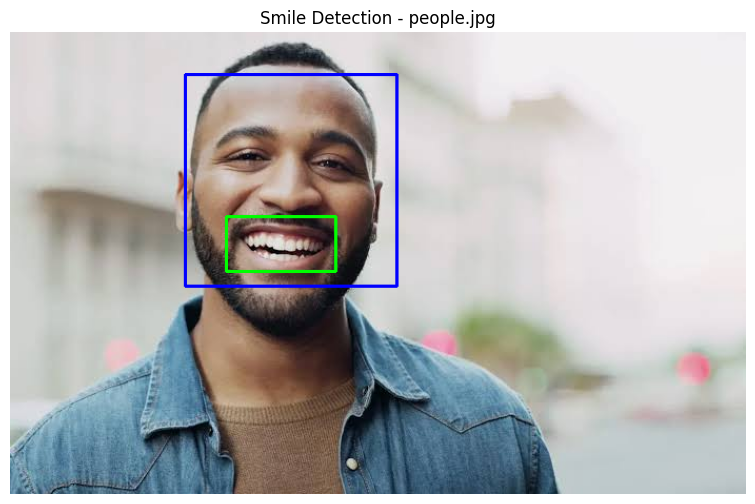

Sumber gambar: people.jpg
Jumlah wajah: 1 | Wajah dengan deteksi senyum: 1


In [ ]:
try:
    try:
        file_smile = cari_file('people.jpg')
        sumber_smile = 'people.jpg'
    except FileNotFoundError:
        file_smile = cari_file('solvayconf.jpg')
        sumber_smile = 'solvayconf.jpg (pengganti people.jpg yang tidak tersedia)'

    people = cv.imread(str(file_smile), cv.IMREAD_COLOR)
    if people is None:
        raise ValueError(f'OpenCV gagal membaca gambar: {file_smile}')

    gray = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
    cascade_wajah = baca_cascade('haarcascade_frontalface_alt.xml')
    cascade_senyum = baca_cascade('haarcascade_smile.xml')

    hasil = people.copy()
    roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
    jumlah_wajah_tersenyum = 0
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 0, 0), 2)
        roi_gray = gray[y:y + h, x:x + w]
        senyum = cascade_senyum.detectMultiScale(
            roi_gray, scaleFactor=1.7, minNeighbors=20, minSize=(25, 25)
        )
        for (sx, sy, sw, sh) in senyum:
            cv.rectangle(hasil, (x + sx, y + sy), (x + sx + sw, y + sy + sh), (0, 255, 0), 2)
        if len(senyum) > 0:
            jumlah_wajah_tersenyum += 1

    plt.figure(figsize=(10, 6))
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title('Smile Detection - ' + sumber_smile)
    plt.axis('off')
    plt.show()
    print('Sumber gambar:', sumber_smile)
    print('Jumlah wajah:', len(roi_wajah), '| Wajah dengan deteksi senyum:', jumlah_wajah_tersenyum)
except FileNotFoundError as e:
    print('Smile Detection dilewati:', e)

**Hasil dan pembahasan:** Classifier senyuman mencari pola visual pada area wajah. Hasil deteksi dipengaruhi posisi wajah, ekspresi, pencahayaan, dan nilai parameter `minNeighbors`.

## Langkah 14: Face Tracking Menggunakan Kamera Google Colab

Face tracking dilakukan dengan mengambil frame dari webcam melalui browser, kemudian memproses setiap frame menggunakan OpenCV. Program mendeteksi wajah dan menampilkan kotak pada area wajah secara langsung. Proses dihentikan melalui tombol **Hentikan kamera** pada tampilan webcam.

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
import base64
import json

IN_COLAB = True

_CAMERA_JS = r"""
window.pcvkCamera = {
  root: null, video: null, overlay: null, status: null, stream: null,
  captureCanvas: null, stopRequested: false,
  async start() {
    this.stop();
    this.stopRequested = false;
    this.root = document.createElement('div');
    this.root.style.cssText = 'max-width:660px;padding:10px;border:1px solid #888;border-radius:8px;margin:8px 0;background:#fff;color:#111;';
    this.status = document.createElement('div');
    this.status.textContent = 'Meminta izin kamera...';
    this.status.style.cssText = 'font-weight:bold;margin-bottom:8px;';
    this.root.appendChild(this.status);

    const stage = document.createElement('div');
    stage.style.cssText = 'position:relative;width:100%;max-width:640px;line-height:0;';
    this.video = document.createElement('video');
    this.video.setAttribute('playsinline', '');
    this.video.autoplay = true;
    this.video.muted = true;
    this.video.style.cssText = 'display:block;width:100%;height:auto;background:#222;';
    this.overlay = document.createElement('canvas');
    this.overlay.style.cssText = 'position:absolute;left:0;top:0;width:100%;height:100%;pointer-events:none;';
    stage.appendChild(this.video);
    stage.appendChild(this.overlay);
    this.root.appendChild(stage);

    const stopButton = document.createElement('button');
    stopButton.textContent = 'Hentikan kamera';
    stopButton.style.cssText = 'margin-top:8px;padding:7px 12px;cursor:pointer;';
    stopButton.onclick = () => this.stop();
    this.root.appendChild(stopButton);
    document.body.appendChild(this.root);

    try {
      if (!navigator.mediaDevices || !navigator.mediaDevices.getUserMedia) {
        throw new Error('Browser tidak menyediakan akses webcam. Gunakan Chrome melalui HTTPS.');
      }
      this.stream = await navigator.mediaDevices.getUserMedia({
        video: {facingMode: {ideal: 'user'}, width: {ideal: 640}, height: {ideal: 480}},
        audio: false
      });
      this.video.srcObject = this.stream;
      await this.video.play();
      this.overlay.width = this.video.videoWidth || 640;
      this.overlay.height = this.video.videoHeight || 480;
      this.captureCanvas = document.createElement('canvas');
      this.captureCanvas.width = this.overlay.width;
      this.captureCanvas.height = this.overlay.height;
      this.status.textContent = 'Kamera aktif. Arahkan wajah ke kamera; klik Hentikan kamera untuk selesai.';
      return {ok: true, width: this.overlay.width, height: this.overlay.height};
    } catch (e) {
      this.status.textContent = 'Kamera gagal: ' + (e.name || 'Error') + ' — ' + e.message;
      return {ok: false, error: (e.name || 'Error') + ': ' + e.message};
    }
  },
  async capture() {
    if (this.stopRequested) return {stopped: true};
    if (!this.video || this.video.readyState < 2) return {ready: false};
    const ctx = this.captureCanvas.getContext('2d');
    ctx.drawImage(this.video, 0, 0, this.captureCanvas.width, this.captureCanvas.height);
    return {ready: true, stopped: false, img: this.captureCanvas.toDataURL('image/jpeg', 0.85)};
  },
  render(label, boxes) {
    if (!this.overlay || this.stopRequested) return;
    this.status.textContent = label;
    const ctx = this.overlay.getContext('2d');
    ctx.clearRect(0, 0, this.overlay.width, this.overlay.height);
    ctx.strokeStyle = '#00ff55';
    ctx.lineWidth = 3;
    ctx.font = '18px Arial';
    ctx.fillStyle = '#00ff55';
    (boxes || []).forEach(b => {
      ctx.strokeRect(b.x, b.y, b.w, b.h);
      ctx.fillText('Wajah', b.x, Math.max(20, b.y - 6));
    });
  },
  stop() {
    this.stopRequested = true;
    if (this.stream) this.stream.getTracks().forEach(track => track.stop());
    this.stream = null;
    if (this.root) this.root.remove();
    this.root = null; this.video = null; this.overlay = null;
    this.status = null; this.captureCanvas = null;
  }
};
"""

def js_to_image(js_reply):
    """Terima respons dictionary dari webcam atau data URL secara langsung."""
    if isinstance(js_reply, dict):
        js_reply = js_reply.get('img')
    if not js_reply or ',' not in js_reply:
        return None
    image_bytes = base64.b64decode(js_reply.split(',', 1)[1])
    image_array = np.frombuffer(image_bytes, dtype=np.uint8)
    return cv.imdecode(image_array, cv.IMREAD_COLOR)

def video_stream():
    display(Javascript(_CAMERA_JS))
    result = eval_js('window.pcvkCamera.start()')
    if not result or not result.get('ok'):
        detail = result.get('error', 'Browser tidak mengembalikan status kamera.') if result else 'Browser tidak mengembalikan status kamera.'
        raise RuntimeError(detail)
    print(f"Webcam aktif: {result['width']} x {result['height']}")

def video_frame(label, boxes):
    eval_js(f"window.pcvkCamera.render({json.dumps(str(label))}, {json.dumps(boxes)})")
    return eval_js('window.pcvkCamera.capture()')

def video_stop():
    try:
        eval_js('window.pcvkCamera.stop()')
    except Exception:
        pass

In [ ]:
cascade_wajah = baca_cascade('haarcascade_frontalface_alt.xml')
if cascade_wajah.empty():
    raise RuntimeError('Haar Cascade frontal face gagal dimuat.')

if not IN_COLAB:
    print('Face Tracking live harus dijalankan di Google Colab.')
else:
    jumlah_frame = 0
    bbox = []
    label_html = 'Menyiapkan kamera...'
    try:
        video_stream()
        print('Video seharusnya tampil di bawah output cell ini. Klik tombol Hentikan kamera untuk selesai.')
        while True:
            js_reply = video_frame(label_html, bbox)
            if not js_reply:
                raise RuntimeError('Browser tidak mengembalikan respons frame. Periksa izin kamera Chrome.')
            if js_reply.get('stopped'):
                print('Face Tracking dihentikan oleh pengguna.')
                break
            if not js_reply.get('ready') or not js_reply.get('img'):
                continue

            frame = js_to_image(js_reply['img'])
            if frame is None:
                raise RuntimeError('Frame kamera diterima tetapi gagal didekode oleh OpenCV.')

            gray_frame = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            wajah = cascade_wajah.detectMultiScale(
                gray_frame, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
            )
            bbox = [
                {'x': int(x), 'y': int(y), 'w': int(w), 'h': int(h)}
                for (x, y, w, h) in wajah
            ]
            jumlah_frame += 1
            label_html = f'{len(wajah)} wajah terdeteksi | frame: {jumlah_frame}'
    except Exception as e:
        print(f'Face Tracking gagal: {type(e).__name__}: {e}')
        print('Pastikan kamera tersambung, izin kamera Chrome = Allow, dan tab Colab tidak diblokir.')
    finally:
        video_stop()
        print('Webcam ditutup.')

**Hasil dan pembahasan:** Setiap frame video diproses untuk mendeteksi wajah. Koordinat wajah yang diperoleh digunakan untuk menggambar kotak pada tampilan video. Proses ini memerlukan Google Colab, izin akses kamera dari browser, dan koneksi internet.

## Langkah 15: Blurring pada Wajah yang Terdeteksi

In [ ]:
img = baca_warna('prabowo.jpg')
asli = img.copy()
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
cascade_wajah = baca_cascade('haarcascade_frontalface_alt.xml')
roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)

for (x, y, w, h) in roi_wajah:
    roi = img[y:y + h, x:x + w]
    ukuran_kernel = 51 if min(w, h) >= 51 else max(3, (min(w, h) // 2) * 2 + 1)
    img[y:y + h, x:x + w] = cv.medianBlur(roi, ukuran_kernel)

plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(asli, cv.COLOR_BGR2RGB))
plt.title('Sebelum blur')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Sesudah blur')
plt.axis('off')
plt.show()
print('Jumlah wajah yang di-blur:', len(roi_wajah))

**Hasil dan pembahasan:** `medianBlur` diterapkan pada area wajah yang terdeteksi untuk menyamarkan identitas pada citra. Hasil visual menunjukkan bagian wajah yang berhasil dikenai efek blur.

## Langkah 16: Pengolahan Kartu Tanda Mahasiswa

Pengolahan KTM terdiri atas tiga bagian, yaitu menampilkan citra KTM, mengambil area pas foto, dan mencari keberadaan KTM pada citra yang berisi objek lain.

Pada pencocokan fitur KTM, diperlukan dua citra: `KTM1b.jpg` sebagai citra acuan dan `KTM_scene.jpg` sebagai citra sumber. Citra sumber menampilkan KTM yang sama bersama objek lain, seperti buku, pulpen, atau ponsel.

### Tampilan Dokumen Asli

In [ ]:
ktm = baca_warna(KTM_FILE)
plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
plt.title('KTM milik sendiri')
plt.axis('off')
plt.show()

### Ekstraksi Pas Foto Identitas

Memotong area pas foto di dalam kartu secara otomatis dengan basis koordinat deteksi wajah.

In [ ]:
H, W = ktm.shape[:2]
MANUAL_CROP = None

if MANUAL_CROP is not None:
    x1, y1, x2, y2 = MANUAL_CROP
    foto = ktm[y1:y2, x1:x2]
else:
    gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
    cascade_wajah = baca_cascade('haarcascade_frontalface_alt.xml')
    roi_wajah = cascade_wajah.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=2)
    print('Kandidat wajah terdeteksi:', len(roi_wajah))

    if len(roi_wajah) == 0:
        raise ValueError(
            'Wajah pada KTM tidak terdeteksi. Isi MANUAL_CROP=(x1, y1, x2, y2) '
            'berdasarkan posisi pas foto pada gambar KTM.'
        )

    x, y, w, h = max(roi_wajah, key=lambda r: r[2] * r[3])
    x1 = max(x - int(0.45 * w), 0)
    x2 = min(x + w + int(0.45 * w), W)
    y1 = max(y - int(0.60 * h), 0)
    y2 = min(y + h + int(0.90 * h), H)
    foto = ktm[y1:y2, x1:x2]

if foto.size == 0:
    raise ValueError('Hasil crop kosong. Periksa koordinat MANUAL_CROP.')

plt.figure(figsize=(5, 6))
plt.imshow(cv.cvtColor(foto, cv.COLOR_BGR2RGB))
plt.title('Crop pas foto KTM')
plt.axis('off')
plt.show()

### Deteksi Kartu Identitas dalam Gambar Kompleks

In [ ]:
try:
    ktm = baca_warna(KTM_FILE)
    scene = baca_warna(KTM_SCENE_FILE)
except FileNotFoundError as e:
    print('Feature Matching KTM belum dijalankan:', e)
    print('Ambil foto KTM yang sama di atas meja bersama beberapa benda lain, lalu simpan sebagai KTM_scene.jpg di folder Images.')
else:
    ktm_gray = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
    scene_gray = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)
    scene_rgb = cv.cvtColor(scene, cv.COLOR_BGR2RGB)

    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(ktm_gray, None)
    kp2, des2 = sift.detectAndCompute(scene_gray, None)

    if des1 is None or des2 is None:
        print('Fitur SIFT tidak cukup ditemukan. Pastikan foto KTM dan KTM_scene jelas/tidak blur.')
    else:
        bf = cv.BFMatcher()
        semua_pasangan = bf.knnMatch(des1, des2, k=2)
        good = []
        for pasangan in semua_pasangan:
            if len(pasangan) == 2:
                m, n = pasangan
                if m.distance < 0.75 * n.distance:
                    good.append(m)

        print('Total pasangan fitur:', len(semua_pasangan))
        print('Pasangan lolos Lowe Ratio Test:', len(good))
        hasil = scene_rgb.copy()
        mask_inlier = None

        if len(good) >= 10:
            src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            M, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

            if M is not None and mask is not None:
                mask_inlier = mask.ravel().tolist()
                h_ktm, w_ktm = ktm_gray.shape
                sudut = np.float32([
                    [0, 0], [0, h_ktm - 1], [w_ktm - 1, h_ktm - 1], [w_ktm - 1, 0]
                ]).reshape(-1, 1, 2)
                sudut_scene = cv.perspectiveTransform(sudut, M)
                hasil = cv.polylines(
                    hasil, [np.int32(sudut_scene)], True, (0, 255, 0), 4, cv.LINE_AA
                )
                print('Jumlah inlier RANSAC:', int(mask.sum()))
            else:
                print('Homografi gagal dihitung. Coba foto yang lebih jelas dan memiliki lebih banyak detail.')
        else:
            print('KTM belum dapat dicocokkan: good matches kurang dari 10.')

        gambar_match = cv.drawMatches(
            cv.cvtColor(ktm_gray, cv.COLOR_GRAY2RGB), kp1,
            hasil, kp2, good, None,
            matchesMask=mask_inlier,
            flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )
        plt.figure(figsize=(14, 7))
        plt.imshow(gambar_match)
        plt.title('Feature Matching KTM - SIFT + Homografi RANSAC')
        plt.axis('off')
        plt.show()

**Hasil dan pembahasan:** SIFT digunakan untuk mencari kesesuaian fitur antara citra KTM acuan dan citra adegan. Pasangan fitur disaring menggunakan Lowe Ratio Test. Homografi dengan RANSAC memperkirakan posisi serta perspektif KTM pada citra adegan apabila jumlah pasangan fitur yang sesuai mencukupi.

# D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN

Pada bagian ini, CNN digunakan untuk mengklasifikasikan satu potongan karakter angka ke dalam kelas 0–9. Model menerima gambar karakter yang telah dipotong dan diubah ukurannya. Model tidak secara langsung menentukan lokasi nomor pada citra KTM secara utuh.

Dataset terdiri atas sepuluh kelas angka. Sebagian contoh angka berasal dari potongan foto KTM, sedangkan angka 3, 5, 8, dan 9 berasal dari kolase sintetis yang dipotong menjadi gambar per karakter. Dataset ini digunakan untuk menguji alur persiapan data, pelatihan, dan prediksi CNN.

## Langkah 17: Persiapan Dataset Karakter

Dataset karakter diekstrak dari berkas ZIP ke penyimpanan lokal Colab pada direktori `/content/PCVK_dataset`. Struktur dataset terdiri atas folder `training` dengan subfolder kelas 0–9 dan folder `testing` yang berisi potongan karakter berlabel pada nama berkas.

Ekstraksi ke penyimpanan lokal digunakan agar proses pembacaan gambar selama persiapan data dan pelatihan berlangsung tanpa akses berulang ke Google Drive.

In [ ]:
import zipfile
import shutil
from pathlib import Path
from tqdm.auto import tqdm

if not IN_COLAB:
    raise RuntimeError('Jalankan ekstraksi dataset ini di Google Colab setelah Drive ter-mount.')

DRIVE_ROOT = Path('/content/drive/MyDrive')
nama_zip = [
    'Dataset_KTM_Angka_0-9_DENGAN_TESTING.zip',
    'Dataset_KTM_Angka_0-9.zip'
]
lokasi_zip = [
    DRIVE_ROOT,
    DRIVE_ROOT / 'PCVK' / 'Pertemuan 10',
    DRIVE_ROOT / 'PCVK' / 'Images'
]
zip_path = None
for folder in lokasi_zip:
    for nama in nama_zip:
        kandidat = folder / nama
        if kandidat.is_file():
            zip_path = kandidat
            break
    if zip_path is not None:
        break

if zip_path is None:
    raise FileNotFoundError(
        'ZIP dataset tidak ditemukan. Letakkan Dataset_KTM_Angka_0-9_DENGAN_TESTING.zip '
        'di My Drive atau My Drive/PCVK/Pertemuan 10.'
    )

CNN_DATA_ROOT = Path('/content/PCVK_dataset')
if CNN_DATA_ROOT.exists():
    shutil.rmtree(CNN_DATA_ROOT)
CNN_DATA_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    daftar_file = [item for item in zip_ref.infolist() if not item.is_dir()]
    for item in tqdm(daftar_file, desc='Ekstraksi dataset CNN', unit='file'):

        target = (CNN_DATA_ROOT / item.filename).resolve()
        if CNN_DATA_ROOT.resolve() not in target.parents and target != CNN_DATA_ROOT.resolve():
            raise ValueError(f'Path tidak aman di ZIP: {item.filename}')
        zip_ref.extract(item, CNN_DATA_ROOT)

DATASET_DIR = CNN_DATA_ROOT / 'dataset'
TRAIN_DIR = DATASET_DIR / 'training'
TEST_DIR = DATASET_DIR / 'testing'
kelas_tersedia = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir()) if TRAIN_DIR.is_dir() else []
if kelas_tersedia != [str(i) for i in range(10)]:
    raise ValueError(f'Dataset training harus memiliki kelas 0-9. Ditemukan: {kelas_tersedia}')
jumlah_training = sum(1 for p in TRAIN_DIR.rglob('*') if p.is_file())
jumlah_testing = sum(1 for p in TEST_DIR.rglob('*') if p.is_file()) if TEST_DIR.is_dir() else 0
print('ZIP sumber        :', zip_path)
print('Lokasi ekstraksi  :', CNN_DATA_ROOT)
print('Jumlah file latih :', jumlah_training)
print('Jumlah file uji   :', jumlah_testing)
print('Kelas             :', kelas_tersedia)
print('Ekstraksi selesai.')

In [ ]:
import random
import pickle
from tqdm import tqdm

TRAIN_DIR = DATASET_DIR / 'training'
TEST_DIR = DATASET_DIR / 'testing'
UKURAN_GAMBAR = (100, 100)
EKSTENSI_GAMBAR = {'.jpg', '.jpeg', '.png', '.bmp'}

if not TRAIN_DIR.is_dir():
    raise FileNotFoundError(
        f'Folder training belum ditemukan: {TRAIN_DIR}. Ekstrak dataset ke folder Images/dataset/ terlebih dahulu.'
    )

KELAS_WAJIB = sorted(
    p.name for p in TRAIN_DIR.iterdir()
    if p.is_dir() and p.name.isdigit()
    and any(f.is_file() and f.suffix.lower() in EKSTENSI_GAMBAR for f in p.iterdir())
)
if not KELAS_WAJIB:
    raise ValueError(f'Tidak ada folder kelas berisi gambar di {TRAIN_DIR}.')

if KELAS_WAJIB != [str(i) for i in range(10)]:
    raise ValueError(
        'Dataset harus memiliki semua folder kelas 0 sampai 9. '
        f'Kelas yang ditemukan: {KELAS_WAJIB}. Periksa hasil ekstraksi ZIP.'
    )

training_data = []
jumlah_per_kelas = {}
for class_number, label_text in enumerate(KELAS_WAJIB):
    folder_kelas = TRAIN_DIR / label_text
    file_gambar = sorted(
        p for p in folder_kelas.iterdir()
        if p.is_file() and p.suffix.lower() in EKSTENSI_GAMBAR
    )
    jumlah_per_kelas[label_text] = len(file_gambar)
    if len(file_gambar) < 2:
        raise ValueError(
            f'Folder {folder_kelas} hanya berisi {len(file_gambar)} gambar. Tambahkan lebih banyak contoh.'
        )

    for path_gambar in tqdm(file_gambar, desc=f'Kelas {label_text}'):
        img_array = cv.imread(str(path_gambar), cv.IMREAD_GRAYSCALE)
        if img_array is None:
            print('Lewati gambar yang gagal dibaca:', path_gambar)
            continue
        new_array = cv.resize(img_array, UKURAN_GAMBAR)
        training_data.append([new_array, class_number])

if not training_data:
    raise ValueError('Tidak ada gambar training valid yang berhasil dibaca.')

random.shuffle(training_data)
X = np.array([item[0] for item in training_data], dtype=np.uint8).reshape(-1, 100, 100, 1)
Y = np.array([item[1] for item in training_data], dtype=np.int64)

with open('X.pickle', 'wb') as f:
    pickle.dump(X, f)
with open('Y.pickle', 'wb') as f:
    pickle.dump(Y, f)
with open('kelas.pickle', 'wb') as f:
    pickle.dump(KELAS_WAJIB, f)

print('Jumlah data training:', len(training_data))
print('Jumlah kelas:', len(KELAS_WAJIB), KELAS_WAJIB)
print('Jumlah gambar per kelas:', jumlah_per_kelas)
print('Total gambar:', sum(jumlah_per_kelas.values()))
print('Bentuk X:', X.shape, '| Bentuk Y:', Y.shape)

**Hasil persiapan data:** `X` menyimpan nilai piksel dari setiap gambar karakter, sedangkan `Y` menyimpan label kelasnya. Data tersebut disimpan ke `X.pickle` dan `Y.pickle` agar dapat dimuat kembali pada tahap pelatihan. Urutan nama kelas disimpan pada `kelas.pickle` untuk mengubah indeks hasil prediksi menjadi karakter angka.

## Langkah 18: Pelatihan CNN

Pada tahap ini, CNN dilatih untuk mempelajari pola visual karakter angka 0–9. Lapisan konvolusi digunakan untuk mengekstraksi fitur gambar secara otomatis, kemudian lapisan *fully connected* menghasilkan prediksi kelas angka.

In [ ]:
import pickle
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

with open('X.pickle', 'rb') as f:
    X = pickle.load(f)
with open('Y.pickle', 'rb') as f:
    Y = pickle.load(f)
with open('kelas.pickle', 'rb') as f:
    kelas = pickle.load(f)

if len(X) != len(Y) or len(X) == 0:
    raise ValueError('Data X dan Y kosong atau jumlahnya tidak sama. Ulangi persiapan dataset.')
if len(np.unique(Y)) < len(kelas):
    raise ValueError('Ada kelas yang tidak memiliki contoh training. Periksa folder dataset.')

X = X.astype('float32') / 255.0
Y_onehot = to_categorical(Y, num_classes=len(kelas))
width, height = 100, 100

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(len(kelas), activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

riwayat = model.fit(
    X, Y_onehot,
    epochs=20,
    batch_size=32,
    verbose=1,
    validation_split=0.2,
    shuffle=True
)
model.save('anpr.keras')

print('Akurasi training :', round(riwayat.history['accuracy'][-1], 4))
print('Akurasi validasi :', round(riwayat.history['val_accuracy'][-1], 4))

**Hasil pelatihan:** Model CNN disimpan dalam berkas `anpr.keras`. Akurasi pelatihan menunjukkan ketepatan model pada data yang digunakan untuk belajar, sedangkan akurasi validasi dihitung dari bagian data pelatihan yang dipisahkan melalui `validation_split=0.2`.

**Batasan evaluasi:** Beberapa kelas menggunakan gambar sintetis dan setiap kelas diperbanyak melalui augmentasi dari sejumlah kecil gambar sumber. Karena pembagian validasi dilakukan setelah augmentasi, gambar yang sangat mirip dapat masuk ke data pelatihan dan validasi. Oleh sebab itu, akurasi validasi belum mewakili kemampuan model pada KTM lain. Pengujian yang lebih kuat memerlukan gambar KTM berbeda yang tidak digunakan pada pelatihan.

## Langkah 19: Pengujian dan Prediksi Karakter

Pengujian dilakukan pada potongan karakter yang telah dipisahkan dari citra KTM. Setiap gambar diproses dengan ukuran dan normalisasi yang sama seperti data pelatihan. Model kemudian memprediksi kelas setiap karakter dan menggabungkan hasil prediksi sesuai urutan berkas.

In [ ]:
import pickle
import pandas as pd
from IPython.display import display

MODEL_PATH = Path('anpr.keras')
KELAS_PATH = Path('kelas.pickle')
EKSTENSI_UJI = {'.jpg', '.jpeg', '.png', '.bmp'}

if not MODEL_PATH.is_file() or not KELAS_PATH.is_file():
    raise FileNotFoundError('Model belum tersedia. Jalankan persiapan data dan Training CNN sampai selesai.')
if not TEST_DIR.is_dir():
    raise FileNotFoundError(f'Folder testing tidak ditemukan: {TEST_DIR}')

file_uji = sorted(
    p for p in TEST_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in EKSTENSI_UJI
)
if not file_uji:
    print('Folder testing masih kosong. Gunakan ZIP Dataset_KTM_Angka_0-9_DENGAN_TESTING.zip.')
else:
    model = tf.keras.models.load_model(str(MODEL_PATH))
    with open(KELAS_PATH, 'rb') as f:
        kelas = pickle.load(f)

    hasil = []
    for file_gambar in file_uji:
        img_gray = cv.imread(str(file_gambar), cv.IMREAD_GRAYSCALE)
        if img_gray is None:
            print('Gagal membaca:', file_gambar)
            continue

        img_resized = cv.resize(img_gray, (100, 100))
        x_input = img_resized.astype('float32').reshape(1, 100, 100, 1) / 255.0
        probabilitas = model.predict(x_input, verbose=0)[0]
        urutan = np.argsort(probabilitas)[::-1]
        idx_prediksi = int(urutan[0])
        prediksi = str(kelas[idx_prediksi])
        confidence = float(probabilitas[idx_prediksi])

        bagian_label = file_gambar.stem.rsplit('_', 1)[-1]
        label_benar = bagian_label if bagian_label in [str(x) for x in kelas] else None
        top3 = ', '.join(f'{kelas[int(i)]} ({probabilitas[int(i)]:.1%})' for i in urutan[:3])

        hasil.append({
            'File': file_gambar.name,
            'Label benar': label_benar if label_benar is not None else '-',
            'Prediksi': prediksi,
            'Confidence': confidence,
            'Benar?': (prediksi == label_benar) if label_benar is not None else None,
            'Top-3 kelas': top3
        })

    if hasil:
        df_hasil = pd.DataFrame(hasil)
        display(df_hasil.style.format({'Confidence': '{:.1%}'}))

        label_berlabel = [r for r in hasil if r['Label benar'] != '-']
        if label_berlabel:
            nomor_sebenarnya = ''.join(r['Label benar'] for r in label_berlabel)
            nomor_prediksi = ''.join(r['Prediksi'] for r in label_berlabel)
            jumlah_benar = sum(r['Benar?'] for r in label_berlabel)
            akurasi_uji = jumlah_benar / len(label_berlabel)
            print('\nNomor sebenarnya :', nomor_sebenarnya)
            print('Hasil prediksi    :', nomor_prediksi)
            print(f'Akurasi karakter  : {jumlah_benar}/{len(label_berlabel)} = {akurasi_uji:.1%}')
            if akurasi_uji < 1.0:
                print('PERHATIAN: model belum mampu mengenali semua crop KTM uji dengan benar.')
                print('Periksa kolom Top-3 dan gambar crop. Akurasi validasi 100% sebelumnya tidak menjamin generalisasi.')
        else:
            print('Nama file tidak memuat label benar. Pakai pola nama seperti 01_2.png agar evaluasi bisa dihitung.')

**Pembahasan hasil pengujian:** Label sebenarnya dibaca dari nama berkas, misalnya `01_2.png` menunjukkan karakter angka 2. Hasil pengujian menampilkan label sebenarnya, prediksi model, nilai kepercayaan (*confidence*), tiga kelas dengan probabilitas tertinggi, dan akurasi per karakter. Perbedaan antara label dan prediksi menunjukkan bahwa model belum mengenali seluruh karakter uji dengan tepat.

**Batasan dataset:** Jumlah 400 gambar pelatihan tidak sama dengan 400 contoh asli yang independen. Setiap kelas hanya memiliki sejumlah kecil gambar sumber dan sisanya merupakan hasil augmentasi. Pembagian acak setelah augmentasi dapat menghasilkan gambar yang sangat mirip pada data pelatihan dan validasi. Model juga hanya menerima potongan karakter satu per satu. Pembacaan nomor KTM secara otomatis masih memerlukan tahap deteksi area nomor dan segmentasi karakter.

---

## Urutan Pelaksanaan Praktikum

1. Melakukan impor library, menghubungkan Google Drive, dan menentukan direktori gambar praktikum.
2. Menyelesaikan D1, meliputi template matching, edge detection, corner detection, grid detection, dan contour detection.
3. Menyelesaikan D2, meliputi ORB, SIFT, face detection, eyes detection, smile detection, face tracking, dan blurring.
4. Menampilkan KTM dan mengambil area pas foto. Pencocokan KTM pada citra adegan menggunakan `KTM1b.jpg` sebagai citra acuan dan memerlukan `KTM_scene.jpg` sebagai citra sumber.
5. Menyiapkan dataset karakter angka 0–9, membentuk array `X` dan label `Y`, kemudian melatih CNN.
6. Menguji model menggunakan potongan karakter pada folder testing dan membandingkan hasil prediksi dengan label sebenarnya.

Model hasil pelatihan disimpan sebagai `anpr.keras`. Pengujian pada notebook ini dilakukan terhadap potongan karakter, bukan pembacaan nomor dari KTM utuh.